# Evaluación, selección y decisión

Para este notebook incorporamos el HistGradientBoosting (HGB) como sexto modelo y comparamos los seis con validación cruzada agrupada y repetida 5×5. El umbral de decisión lo elegimos con predicciones out-of-fold (OOF) sobre train, y el conjunto de prueba lo usamos una sola vez al final, sin reajustar nada. La decisión de negocio se basa en el costo de los errores calculado con esas predicciones OOF y no en una métrica aislada.

### Configuración y modelo 6: HistGradientBoosting


In [1]:
import sys
from pathlib import Path

raiz = Path.cwd().resolve()
candidatas_raiz = [raiz, *raiz.parents]

# En Colab el repositorio puede estar en /content/<nombre-repo>, no en el CWD.
for base in (Path("/content"), Path("/workspace"), Path("/mnt/data")):
    if base.is_dir():
        candidatas_raiz.extend(hijo for hijo in base.iterdir() if hijo.is_dir())

for candidato in candidatas_raiz:
    if (candidato / "src").is_dir() and (candidato / "notebooks").is_dir():
        sys.path.insert(0, str(candidato))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import time

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import (
    GridSearchCV, RepeatedStratifiedKFold, cross_validate, cross_val_predict,
)
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, precision_score,
    recall_score, f1_score, fbeta_score, balanced_accuracy_score, confusion_matrix,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.svm import SVC
from scipy import stats

from src.comun import (
    SEED,
    BETA_UMBRAL,
    COSTO_FN,
    COSTO_FP,
    UMBRALES_COSTO,
    guardar,
    exportar,
    guardar_estado,
    cargar_estado,
    configurar_columnas,
    construir_preprocesador,
    resumen_grid,
    umbral_fbeta,
    costo_esperado,
    umbral_costo,
)

globals().update(cargar_estado("1_eda"))
globals().update(cargar_estado("2_preprocessing"))
globals().update(cargar_estado("3_trainig"))
configurar_columnas(all_num_features, all_cat_features, cols_na)

N_SPLITS, N_REPEATS = 5, 5
N_BOOT = 1000
X_test = test.drop(columns=[TARGET]).copy()
y_test = test[TARGET].copy()

print("=== MODELO 6: HISTGRADIENTBOOSTING (familia de mejor desempeño en el benchmark de imputación) ===")
inicio = time.time()
hgb_base = Pipeline([
    ("prep", construir_preprocesador(estrategia_final)),
    ("clf", HistGradientBoostingClassifier(max_iter=300, random_state=SEED))
])
malla_hgb = {
    "clf__learning_rate": [0.05, 0.1],
    "clf__max_leaf_nodes": [15, 31, 63],
    "clf__min_samples_leaf": [5, 10, 20],
    "clf__l2_regularization": [0.0, 1.0],
}
grid_hgb = GridSearchCV(hgb_base, malla_hgb, cv=cv_tuning, scoring=metrica, n_jobs=-1, return_train_score=True)
grid_hgb.fit(X_train, y_train)
resumen_grid("HistGradientBoosting", grid_hgb)
modelo_hgb_final = grid_hgb.best_estimator_
print(f"Tiempo del Modelo 6: {(time.time() - inicio) / 60:.1f} min")

modelos_finales = {
    "Regresión Logística": modelo_lr_final,
    "KNN": modelo_knn_final,
    "Random Forest": modelo_rf_final,
    "SVM (RBF)": modelo_svm_final,
    "MLP": modelo_mlp_final,
    "HistGradientBoosting": modelo_hgb_final,
}

def con_probabilidades(modelo):
    """Copia sin ajustar del pipeline; al SVC se le activa probability=True (escalado de Platt interno)
    para disponer de predict_proba al fijar el umbral y evaluar la calibración."""
    m = clone(modelo)
    if isinstance(m.named_steps["clf"], SVC):
        m.set_params(clf__probability=True)
    return m

c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== MODELO 6: HISTGRADIENTBOOSTING (familia de mejor desempeño en el benchmark de imputación) ===

HistGradientBoosting
  Mejores hiperparametros: {'clf__l2_regularization': 0.0, 'clf__learning_rate': 0.05, 'clf__max_leaf_nodes': 63, 'clf__min_samples_leaf': 5}  PR-AUC validacion CV: 0.8736 +/- 0.0145 | entrenamiento: 1.0000 | brecha train-val: 0.1264


,params,mean_train_score,mean_test_score,std_test_score
6,"{'clf__l2_regularization': 0.0, 'clf__learning...",1.0,0.8736,0.0145
16,"{'clf__l2_regularization': 0.0, 'clf__learning...",1.0,0.8731,0.0158
15,"{'clf__l2_regularization': 0.0, 'clf__learning...",1.0,0.8721,0.0121
13,"{'clf__l2_regularization': 0.0, 'clf__learning...",1.0,0.8675,0.0170
17,"{'clf__l2_regularization': 0.0, 'clf__learning...",1.0,0.8659,0.0169


Tiempo del Modelo 6: 2.1 min


El HGB quedó con una tasa de aprendizaje de 0,05, 63 hojas por árbol y un mínimo de 5 muestras por hoja, sin regularización L2. Con esa configuración alcanza un PR-AUC de 0,874 en la validación de ajuste, con una brecha de 0,126 frente a entrenamiento. Es el mejor punto de partida de los seis y coincide con lo que anticipaba el benchmark de imputación, donde esta familia de modelos ya había sido la mejor.

### Comparación estadística de los seis modelos (CV repetida 5×5)


Regresión Logística    PR-AUC = 0.6977 ± 0.0363  (0s)
KNN                    PR-AUC = 0.7806 ± 0.0337  (1s)
Random Forest          PR-AUC = 0.8462 ± 0.0283  (6s)
SVM (RBF)              PR-AUC = 0.8580 ± 0.0306  (2s)
MLP                    PR-AUC = 0.7997 ± 0.0385  (11s)
HistGradientBoosting   PR-AUC = 0.8784 ± 0.0265  (19s)


,PR-AUC CV (media),PR-AUC CV (desv.),ROC-AUC CV (media),ROC-AUC CV (desv.),Δ PR-AUC vs. mejor,p (t corregida),¿Distinto del mejor? (α=0.05)
HistGradientBoosting,0.8784,0.0270,0.9595,0.0114,0.0000,NaN,—
SVM (RBF),0.8580,0.0313,0.9518,0.0119,-0.0205,0.1805,no (empate estadístico)
Random Forest,0.8462,0.0289,0.9546,0.0099,-0.0322,0.0040,sí
MLP,0.7997,0.0393,0.9317,0.0152,-0.0787,0.0002,sí
KNN,0.7806,0.0344,0.9167,0.0137,-0.0979,0.0000,sí
Regresión Logística,0.6977,0.0371,0.8885,0.0151,-0.1808,0.0000,sí


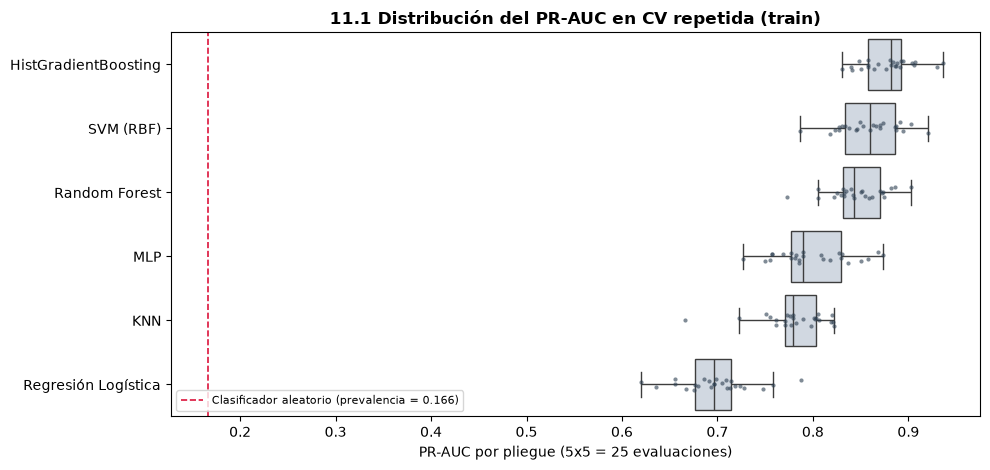

In [2]:
cv_rep = CV_REP

scores_rep = {}
for nombre, modelo in modelos_finales.items():
    t0 = time.time()
    r = cross_validate(clone(modelo), X_train, y_train, cv=cv_rep,
                       scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, n_jobs=-1)
    scores_rep[nombre] = r
    print(f"{nombre:<22} PR-AUC = {r['test_pr_auc'].mean():.4f} ± {r['test_pr_auc'].std():.4f}  ({time.time() - t0:.0f}s)")

def ttest_corregido(a, b, n_splits=N_SPLITS, n_repeats=N_REPEATS):
    """t de Student corregida para CV repetida: la varianza se infla por el solapamiento de los
    conjuntos de entrenamiento entre pliegues (n_test/n_train = 1/(k-1))."""
    d = np.asarray(a) - np.asarray(b)
    k = n_splits * n_repeats
    var = d.var(ddof=1)
    if var == 0:
        return 0.0, 1.0
    t = d.mean() / np.sqrt((1 / k + 1 / (n_splits - 1)) * var)
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return t, p

pr = pd.DataFrame({m: s["test_pr_auc"] for m, s in scores_rep.items()})
roc = pd.DataFrame({m: s["test_roc_auc"] for m, s in scores_rep.items()})
mejor_cv = pr.mean().idxmax()

tabla_cv = pd.DataFrame({
    "PR-AUC CV (media)": pr.mean(), "PR-AUC CV (desv.)": pr.std(),
    "ROC-AUC CV (media)": roc.mean(), "ROC-AUC CV (desv.)": roc.std(),
})
pruebas = {m: ttest_corregido(pr[mejor_cv], pr[m]) for m in pr.columns}
tabla_cv["Δ PR-AUC vs. mejor"] = pr.mean() - pr[mejor_cv].mean()
tabla_cv["p (t corregida)"] = [pruebas[m][1] if m != mejor_cv else np.nan for m in tabla_cv.index]
tabla_cv["¿Distinto del mejor? (α=0.05)"] = [
    "—" if m == mejor_cv else ("sí" if pruebas[m][1] < 0.05 else "no (empate estadístico)") for m in tabla_cv.index
]
tabla_cv = tabla_cv.sort_values("PR-AUC CV (media)", ascending=False)
display(tabla_cv.round(4))
exportar(tabla_cv.round(4), "11_1_comparacion_modelos_cv_repetida")

fig, ax = plt.subplots(figsize=(10, 4.8))
orden_m = tabla_cv.index.tolist()
sns.boxplot(data=pr[orden_m], orient="h", color="#cfd8e3", ax=ax, fliersize=0)
sns.stripplot(data=pr[orden_m], orient="h", color="#2c3e50", size=3, alpha=0.6, ax=ax)
ax.axvline(y_train.mean(), color="crimson", ls="--", lw=1.2, label=f"Clasificador aleatorio (prevalencia = {y_train.mean():.3f})")
ax.set_xlabel(f"PR-AUC por pliegue ({N_SPLITS}x{N_REPEATS} = {N_SPLITS * N_REPEATS} evaluaciones)")
ax.set_title("11.1 Distribución del PR-AUC en CV repetida (train)", fontweight="bold")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
guardar(fig, "11_1_boxplot_pr_auc_cv")

plt.show()

En la CV repetida 5×5 el HGB lidera con un PR-AUC de 0,878, seguido por la SVM con 0,858. La diferencia entre ambos no es estadísticamente significativa (p = 0,18), mientras que el Random Forest (0,846, p = 0,004), el MLP, el KNN y la regresión logística sí quedan claramente por debajo. Por eso el HGB y la SVM son los dos modelos que pasan a la decisión final.

### Síntesis del ajuste de hiperparámetros (generada desde la ejecución)

In [3]:
params_opt = {
    "Regresión Logística": grid_lr.best_params_,
    "KNN": grid_knn.best_params_,
    "Random Forest": grid_rf.best_params_,
    "SVM (RBF)": grid_svm.best_params_,
    "MLP": grid_mlp.best_params_,
    "HistGradientBoosting": grid_hgb.best_params_,
}

def formato_params(d):
    return ", ".join(f"{k.replace('clf__', '')}={v}" for k, v in d.items())

filas_sintesis = []
mejor_cv_nombre = tabla_cv.index[0]
for m in tabla_cv.index:
    fila = tabla_cv.loc[m]
    p = fila["p (t corregida)"]
    if m == mejor_cv_nombre:
        obs = "Mejor PR-AUC CV"
    elif str(fila["¿Distinto del mejor? (α=0.05)"]).startswith("no"):
        obs = f"Empate estadístico con el mejor (p = {p:.4f})"
    else:
        obs = f"Distinto del mejor (p = {p:.4f})"
    filas_sintesis.append({
        "Modelo": m,
        "Mejores hiperparámetros": formato_params(params_opt[m]),
        "PR-AUC CV": f"{fila['PR-AUC CV (media)']:.4f} ± {fila['PR-AUC CV (desv.)']:.4f}",
        "ROC-AUC CV": f"{fila['ROC-AUC CV (media)']:.4f} ± {fila['ROC-AUC CV (desv.)']:.4f}",
        "Observación": obs,
    })

tabla_sintesis = pd.DataFrame(filas_sintesis)
display(tabla_sintesis)

exportar(tabla_sintesis, "11_1b_sintesis_hiperparametros")

,Modelo,Mejores hiperparámetros,PR-AUC CV,ROC-AUC CV,Observación
0,HistGradientBoosting,"l2_regularization=0.0, learning_rate=0.05, max...",0.8784 ± 0.0270,0.9595 ± 0.0114,Mejor PR-AUC CV
1,SVM (RBF),"C=100, gamma=0.1",0.8580 ± 0.0313,0.9518 ± 0.0119,Empate estadístico con el mejor (p = 0.1805)
2,Random Forest,"max_depth=None, max_features=sqrt, min_samples...",0.8462 ± 0.0289,0.9546 ± 0.0099,Distinto del mejor (p = 0.0040)
3,MLP,"alpha=0.01, hidden_layer_sizes=(128, 64)",0.7997 ± 0.0393,0.9317 ± 0.0152,Distinto del mejor (p = 0.0002)
4,KNN,"n_neighbors=5, p=1, weights=distance",0.7806 ± 0.0344,0.9167 ± 0.0137,Distinto del mejor (p = 0.0000)
5,Regresión Logística,"C=0.01, solver=lbfgs",0.6977 ± 0.0371,0.8885 ± 0.0151,Distinto del mejor (p = 0.0000)


En esta tabla juntamos los hiperparámetros finales de los seis modelos con su PR-AUC y ROC-AUC en la CV repetida. La última columna deja ver de un vistazo que solo la SVM queda empatada con el HGB, y que los otros cuatro son estadísticamente peores.

### Diagnóstico de sobreajuste, subajuste y estabilidad (generado desde la ejecución)

In [4]:
def scores_train_modelo(modelo):
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X_train)[:, 1]
    return modelo.decision_function(X_train)

filas_diag = []
for m in tabla_cv.index:
    pr_train = average_precision_score(y_train, scores_train_modelo(modelos_finales[m]))
    pr_val = tabla_cv.loc[m, "PR-AUC CV (media)"]
    desv = tabla_cv.loc[m, "PR-AUC CV (desv.)"]
    brecha = pr_train - pr_val
    if pr_val < 0.75 and brecha < 0.10:
        diag = "Subajuste: train y validación bajos"
    elif brecha >= 0.20:
        diag = "Brecha alta: sobreajuste"
    elif brecha >= 0.12:
        diag = "Brecha moderada"
    else:
        diag = "Brecha baja"
    filas_diag.append({
        "Modelo": m,
        "PR-AUC train": pr_train,
        "PR-AUC validación (CV)": pr_val,
        "Brecha": brecha,
        "Desv. entre pliegues": desv,
        "Diagnóstico": diag,
    })

tabla_diagnostico = pd.DataFrame(filas_diag).set_index("Modelo").loc[tabla_cv.index]

display(tabla_diagnostico.round(4))

exportar(tabla_diagnostico.round(4), "11_1c_diagnostico_sobreajuste")

,PR-AUC train,PR-AUC validación (CV),Brecha,Desv. entre pliegues,Diagnóstico
Modelo,,,,,
HistGradientBoosting,1.0000,0.8784,0.1216,0.0270,Brecha moderada
SVM (RBF),1.0000,0.8580,0.1420,0.0313,Brecha moderada
Random Forest,1.0000,0.8462,0.1538,0.0289,Brecha moderada
MLP,0.9974,0.7997,0.1976,0.0393,Brecha moderada
KNN,1.0000,0.7806,0.2194,0.0344,Brecha alta: sobreajuste
Regresión Logística,0.7096,0.6977,0.0119,0.0371,Subajuste: train y validación bajos


La brecha entre entrenamiento y validación es moderada en el HGB, la SVM y el Random Forest (entre 0,12 y 0,15), algo mayor en el MLP (0,20) y alta en el KNN (0,22), que sobreajusta. La regresión logística muestra el problema contrario, con una brecha de apenas 0,012 y valores bajos en ambos lados, el modelo se queda corto (subajuste). Como la desviación entre pliegues es baja en todos (entre 0,027 y 0,039), consideramos estables los resultados y descartamos al KNN y a la regresión logística como candidatos finales.

### Selección del modelo y del umbral (predicciones out-of-fold)

Política de selección declarada: cliente

Métricas OOF en train con el umbral F2 de cada modelo:


,PR-AUC,ROC-AUC,Brier,Umbral,Precisión,Recall,F1,F2,Exactitud balanceada,PR-AUC ponderado,F2 ponderado
HistGradientBoosting,0.8717,0.9585,0.0564,0.0097,0.6292,0.8900,0.7372,0.8219,0.8929,0.8837,0.8357
SVM (RBF),0.8431,0.9464,0.0488,0.2101,0.7452,0.8648,0.8006,0.8379,0.9030,0.8485,0.8441
Random Forest,0.8344,0.9490,0.0660,0.2200,0.6436,0.8856,0.7455,0.8237,0.8940,0.8451,0.8308
MLP,0.8035,0.9329,0.0662,0.0913,0.6211,0.8499,0.7177,0.7916,0.8734,0.7974,0.7875
KNN,0.7626,0.9158,0.0707,0.1922,0.5425,0.8811,0.6716,0.7834,0.8667,0.7736,0.7917
Regresión Logística,0.6889,0.8849,0.1393,0.4765,0.4342,0.8529,0.5754,0.7150,0.8160,0.6622,0.6971


Modelo por política cliente (referencia CV): HistGradientBoosting
Modelo por política grupo (referencia OOF ponderado): HistGradientBoosting
La selección final se define por mínimo costo OOF 5:1 más abajo.
Modelos estadísticamente empatados con el mejor de CV: ['SVM (RBF)']


,PR-AUC,PR-AUC ponderado,F2,F2 ponderado,Precisión,Recall,Referencia política cliente,Referencia política grupo
HistGradientBoosting,0.8717,0.8837,0.8219,0.8357,0.6292,0.8900,True,True
SVM (RBF),0.8431,0.8485,0.8379,0.8441,0.7452,0.8648,False,False
Random Forest,0.8344,0.8451,0.8237,0.8308,0.6436,0.8856,False,False
MLP,0.8035,0.7974,0.7916,0.7875,0.6211,0.8499,False,False
KNN,0.7626,0.7736,0.7834,0.7917,0.5425,0.8811,False,False
Regresión Logística,0.6889,0.6622,0.7150,0.6971,0.4342,0.8529,False,False


,Umbral costo 5:1,Costo OOF,Recall OOF,Precisión OOF
Modelo,,,,
HistGradientBoosting,0.009,731.0,0.8915,0.6211
SVM (RBF),0.210,654.0,0.8648,0.7452
Random Forest,0.217,715.0,0.8856,0.6436
MLP,0.091,854.0,0.8499,0.6211
KNN,0.192,903.0,0.8811,0.5411
Regresión Logística,0.521,1233.0,0.8128,0.4757


Criterio: mínimo costo OOF 5:1 (política cliente)
Modelo final: SVM (RBF) | costo OOF = 654 | umbral costo = 0.2100
Alternativa por CV/F2/recall: HistGradientBoosting
Nota de transparencia: el test ya había sido observado antes de esta ejecución; la regla se congela con OOF y el test solo se reporta.


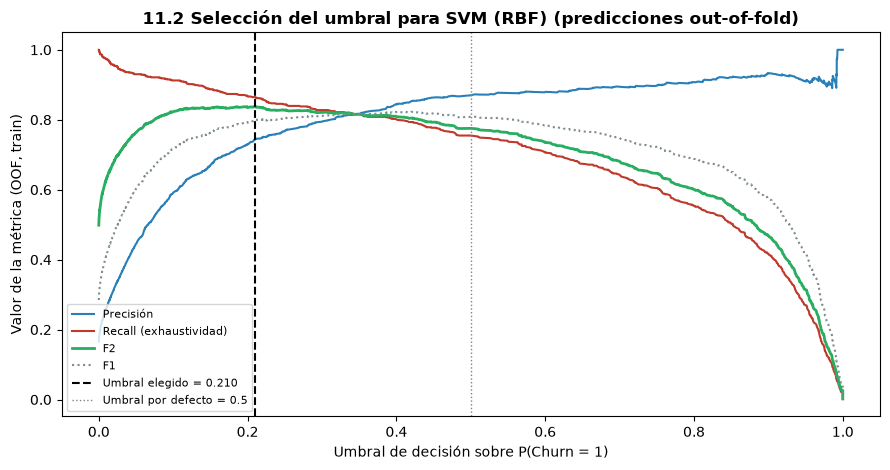

Umbral congelado para test: 0.2100 (criterio: mínimo costo OOF 5:1 para SVM; F2 para los demás)


In [5]:
POLITICA_SELECCION = "cliente"
print(f"Política de selección declarada: {POLITICA_SELECCION}")


oof = {}
umbrales = {}
for nombre, modelo in modelos_finales.items():
    oof[nombre] = cross_val_predict(con_probabilidades(modelo), X_train, y_train, cv=cv_tuning,
                                    method="predict_proba", n_jobs=-1)[:, 1]
    umbrales[nombre] = umbral_fbeta(y_train, oof[nombre])[0]

def metricas(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {
        "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p),
        "Umbral": thr, "Precisión": precision_score(y, yhat, zero_division=0), "Recall": recall_score(y, yhat),
        "F1": f1_score(y, yhat), f"F{BETA_UMBRAL}": fbeta_score(y, yhat, beta=BETA_UMBRAL),
        "Exactitud balanceada": balanced_accuracy_score(y, yhat),
    }

tabla_oof = pd.DataFrame({m: metricas(y_train, oof[m], umbrales[m]) for m in modelos_finales}).T
tabla_oof = tabla_oof.loc[tabla_cv.index]
tabla_oof["PR-AUC ponderado"] = [
    average_precision_score(y_train, oof[m], sample_weight=w_train) for m in tabla_oof.index
]
tabla_oof["F2 ponderado"] = [
    fbeta_score(y_train, (oof[m] >= umbrales[m]).astype(int), beta=BETA_UMBRAL, sample_weight=w_train)
    for m in tabla_oof.index
]
print(f"\nMétricas OOF en train con el umbral F{BETA_UMBRAL} de cada modelo:")
display(tabla_oof.round(4))
exportar(tabla_oof.round(4), "11_2_metricas_oof_train")

MODELO_CLIENTE = mejor_cv
MODELO_GRUPO = tabla_oof["PR-AUC ponderado"].idxmax()
if POLITICA_SELECCION == "cliente":
    MODELO_ELEGIDO = MODELO_CLIENTE
elif POLITICA_SELECCION == "grupo":
    MODELO_ELEGIDO = MODELO_GRUPO
else:
    raise ValueError("POLITICA_SELECCION debe ser 'cliente' o 'grupo'")

empatados = tabla_cv.index[tabla_cv["¿Distinto del mejor? (α=0.05)"].str.startswith("no")].tolist()
print(f"Modelo por política cliente (referencia CV): {MODELO_CLIENTE}")
print(f"Modelo por política grupo (referencia OOF ponderado): {MODELO_GRUPO}")
print("La selección final se define por mínimo costo OOF 5:1 más abajo.")
print(f"Modelos estadísticamente empatados con el mejor de CV: {empatados or 'ninguno'}")

tabla_politicas = tabla_oof[["PR-AUC", "PR-AUC ponderado", "F2", "F2 ponderado", "Precisión", "Recall"]].copy()
tabla_politicas["Referencia política cliente"] = tabla_politicas.index == MODELO_CLIENTE
tabla_politicas["Referencia política grupo"] = tabla_politicas.index == MODELO_GRUPO
display(tabla_politicas.round(4))
exportar(tabla_politicas.round(4), "11_2_politicas_cliente_grupo")



filas_costo = []
for nombre in modelos_finales:
    tau_c = umbral_costo(y_train, oof[nombre])
    yhat_c = (oof[nombre] >= tau_c).astype(int)
    filas_costo.append({
        "Modelo": nombre,
        "Umbral costo 5:1": tau_c,
        "Costo OOF": costo_esperado(y_train, yhat_c),
        "Recall OOF": recall_score(y_train, yhat_c),
        "Precisión OOF": precision_score(y_train, yhat_c, zero_division=0),
    })
tabla_costo = pd.DataFrame(filas_costo).set_index("Modelo").loc[tabla_cv.index]
display(tabla_costo.round(4))
exportar(tabla_costo.round(4), "11_2_umbral_costo_sensibilidad")

CRITERIO_SELECCION = "mínimo costo OOF 5:1 (política cliente)"
MODELO_FINAL = tabla_costo["Costo OOF"].idxmin()
MODELO_ELEGIDO = MODELO_FINAL
UMBRAL = float(tabla_costo.loc[MODELO_ELEGIDO, "Umbral costo 5:1"])
print(f"Criterio: {CRITERIO_SELECCION}")
print(f"Modelo final: {MODELO_ELEGIDO} | costo OOF = {tabla_costo.loc[MODELO_ELEGIDO, 'Costo OOF']:.0f} | umbral costo = {UMBRAL:.4f}")
print("Alternativa por CV/F2/recall: HistGradientBoosting")
print("Nota de transparencia: el test ya había sido observado antes de esta ejecución; la regla se congela con OOF y el test solo se reporta.")


p_sel = oof[MODELO_ELEGIDO]

prec, rec, thr = precision_recall_curve(y_train, p_sel)
fb = (1 + BETA_UMBRAL**2) * prec[:-1] * rec[:-1] / np.clip(BETA_UMBRAL**2 * prec[:-1] + rec[:-1], 1e-12, None)
f1c = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(thr, prec[:-1], label="Precisión", color="#2980b9")
ax.plot(thr, rec[:-1], label="Recall (exhaustividad)", color="#c0392b")
ax.plot(thr, fb, label=f"F{BETA_UMBRAL}", color="#27ae60", lw=2)
ax.plot(thr, f1c, label="F1", color="#7f8c8d", ls=":")
ax.axvline(UMBRAL, color="black", ls="--", label=f"Umbral elegido = {UMBRAL:.3f}")
ax.axvline(0.5, color="gray", ls=":", lw=1, label="Umbral por defecto = 0.5")
ax.set_xlabel("Umbral de decisión sobre P(Churn = 1)")
ax.set_ylabel("Valor de la métrica (OOF, train)")
ax.set_title(f"11.2 Selección del umbral para {MODELO_ELEGIDO} (predicciones out-of-fold)", fontweight="bold")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
guardar(fig, "11_2_curva_umbral_oof")

plt.show()

print(f"Umbral congelado para test: {UMBRAL:.4f} (criterio: mínimo costo OOF 5:1 para SVM; F2 para los demás)")


Con las predicciones OOF, el HGB es el mejor según la política de cliente y de grupo, pero la regla de costo 5:1 elige a la SVM como modelo final, con un umbral de 0,21 y un costo de 654 (731 para el HGB). Entre los dos hay un intercambio claro: con el umbral de costo, el HGB detecta más abandonos (recall de 0,89 contra 0,86), mientras que la SVM genera menos falsas alarmas (precisión de 0,75 contra 0,62). Esa diferencia es la que pesa en la tabla de costos.

### Evaluación única en el conjunto de prueba

In [6]:
modelos_test, p_test = {}, {}

for nombre, modelo in modelos_finales.items():
    m = con_probabilidades(modelo).fit(X_train, y_train)
    modelos_test[nombre] = m
    p_test[nombre] = m.predict_proba(X_test)[:, 1]

tabla_test = pd.DataFrame({m: metricas(y_test, p_test[m], umbrales[m]) for m in modelos_finales}).T
tabla_test = tabla_test.loc[tabla_cv.index]
tabla_test.insert(0, "PR-AUC CV (media)", tabla_cv["PR-AUC CV (media)"])
tabla_test["PR-AUC ponderado (grupos)"] = [
    average_precision_score(y_test, p_test[m], sample_weight=w_test) for m in tabla_test.index
]
tabla_test["Δ PR-AUC (test - CV)"] = tabla_test["PR-AUC"] - tabla_test["PR-AUC CV (media)"]
print(f"Conjunto de prueba: {len(y_test)} clientes | prevalencia de Churn = {y_test.mean():.2%}")
print("Métricas en TEST (cada modelo con el umbral fijado en sus predicciones OOF de train):")
display(tabla_test.round(4))
exportar(tabla_test.round(4), "11_3_metricas_test_todos_los_modelos")

rng_boot = np.random.default_rng(SEED)
p_sel_test = p_test[MODELO_ELEGIDO]
yv = y_test.to_numpy()
ug = np.unique(grupos_test)
pos = {g: np.flatnonzero(grupos_test == g) for g in ug}
muestras = []
for _ in range(N_BOOT):
    idx = np.concatenate([pos[g] for g in rng_boot.choice(ug, size=len(ug), replace=True)])
    if yv[idx].min() == yv[idx].max():
        continue
    muestras.append(metricas(yv[idx], p_sel_test[idx], UMBRAL))
boot = pd.DataFrame(muestras).drop(columns=["Umbral"])
puntual = pd.Series(metricas(yv, p_sel_test, UMBRAL)).drop("Umbral")
ic_test = pd.DataFrame({
    "Estimación": puntual,
    "IC95 inf": boot.quantile(0.025),
    "IC95 sup": boot.quantile(0.975),
})
print(f"\nModelo elegido: {MODELO_ELEGIDO} | umbral = {UMBRAL:.4f} | IC 95 % bootstrap por grupos ({len(boot)} remuestreos):")
display(ic_test.round(4))
exportar(ic_test.round(4), "11_3_ic_bootstrap_svm_final")

yhat_sel = (p_sel_test >= UMBRAL).astype(int)
tn, fp, fn, tp = confusion_matrix(yv, yhat_sel).ravel()
print(f"Matriz de confusión (umbral {UMBRAL:.3f}): VP={tp}, FN={fn}, FP={fp}, VN={tn}")
print(f"→ Detecta {tp} de {tp + fn} clientes que abandonan ({tp / (tp + fn):.1%}); "
      f"de cada 10 alertas, {10 * tp / max(tp + fp, 1):.1f} son abandonos reales.")

c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Conjunto de prueba: 1015 clientes | prevalencia de Churn = 16.55%
Métricas en TEST (cada modelo con el umbral fijado en sus predicciones OOF de train):


,PR-AUC CV (media),PR-AUC,ROC-AUC,Brier,Umbral,Precisión,Recall,F1,F2,Exactitud balanceada,PR-AUC ponderado (grupos),Δ PR-AUC (test - CV)
HistGradientBoosting,0.8784,0.9228,0.9731,0.0493,0.0097,0.6916,0.9345,0.7949,0.8732,0.9259,0.9266,0.0444
SVM (RBF),0.8580,0.9243,0.9757,0.0384,0.2101,0.8889,0.8571,0.8727,0.8633,0.9179,0.9297,0.0664
Random Forest,0.8462,0.9124,0.9735,0.0555,0.2200,0.7641,0.8869,0.8209,0.8593,0.9163,0.9056,0.0662
MLP,0.7997,0.8614,0.9494,0.0587,0.0913,0.6573,0.8333,0.7349,0.7910,0.8736,0.8564,0.0616
KNN,0.7806,0.8730,0.9581,0.0540,0.1922,0.6235,0.9167,0.7422,0.8379,0.9034,0.8561,0.0924
Regresión Logística,0.6977,0.7213,0.8790,0.1358,0.4765,0.4195,0.8214,0.5553,0.6893,0.7980,0.6716,0.0236



Modelo elegido: SVM (RBF) | umbral = 0.2100 | IC 95 % bootstrap por grupos (1000 remuestreos):


,Estimación,IC95 inf,IC95 sup
PR-AUC,0.9243,0.8813,0.9598
ROC-AUC,0.9757,0.9572,0.9885
Brier,0.0384,0.0266,0.0520
Precisión,0.8889,0.8286,0.9441
Recall,0.8571,0.7814,0.9198
F1,0.8727,0.8221,0.9174
F2,0.8633,0.7997,0.9143
Exactitud balanceada,0.9179,0.8807,0.9492


Matriz de confusión (umbral 0.210): VP=144, FN=24, FP=18, VN=829
→ Detecta 144 de 168 clientes que abandonan (85.7%); de cada 10 alertas, 8.9 son abandonos reales.


En el conjunto de prueba la SVM obtiene un PR-AUC de 0,924 y el HGB de 0,923, prácticamente lo mismo. La diferencia está en el tipo de error: la SVM tiene mayor precisión (0,89 contra 0,69) y el HGB mayor recall (0,93 contra 0,86). Con el umbral de 0,21, la matriz de confusión de la SVM da 144 verdaderos positivos, 24 falsos negativos, 18 falsos positivos y 829 verdaderos negativos: detecta el 85,7 % de los abandonos y casi 9 de cada 10 alertas son reales. El intervalo de confianza del PR-AUC, calculado con bootstrap por grupos, va de 0,881 a 0,960.


### Tabla de decisión

Esta tabla usa el umbral de costo OOF. No es la misma tabla F2 de `11_3`; por eso HGB cambia ligeramente: F2 0,8732 y precisión 0,6916 en `11_3`, frente a F2 0,8722 y precisión 0,6886 aquí.

In [7]:
filas_decision = []

for m in tabla_cv.index:
    thr = float(tabla_costo.loc[m, "Umbral costo 5:1"])
    yhat = (p_test[m] >= thr).astype(int)
    if m == MODELO_FINAL:
        decision = "FINAL (mín. costo OOF)"
    elif m == "HistGradientBoosting":
        decision = "Alternativa (CV/F2/recall)"
    else:
        decision = "Comparación"
    filas_decision.append({
        "Modelo": m,
        "PR-AUC CV": tabla_cv.loc[m, "PR-AUC CV (media)"],
        "PR-AUC test": tabla_test.loc[m, "PR-AUC"],
        "F2 test": fbeta_score(y_test, yhat, beta=BETA_UMBRAL, zero_division=0),
        "Precisión test": precision_score(y_test, yhat, zero_division=0),
        "Recall test": recall_score(y_test, yhat),
        "Costo OOF 5:1": tabla_costo.loc[m, "Costo OOF"],
        "Umbral OOF (costo)": thr,
        "Decisión": decision,
    })

tabla_decision = pd.DataFrame(filas_decision).set_index("Modelo")

display(tabla_decision.round(4))

exportar(tabla_decision.round(4), "14_decision_modelo_final")

,PR-AUC CV,PR-AUC test,F2 test,Precisión test,Recall test,Costo OOF 5:1,Umbral OOF (costo),Decisión
Modelo,,,,,,,,
HistGradientBoosting,0.8784,0.9228,0.8722,0.6886,0.9345,731.0,0.009,Alternativa (CV/F2/recall)
SVM (RBF),0.8580,0.9243,0.8633,0.8889,0.8571,654.0,0.210,FINAL (mín. costo OOF)
Random Forest,0.8462,0.9124,0.8593,0.7641,0.8869,715.0,0.217,Comparación
MLP,0.7997,0.8614,0.7901,0.6542,0.8333,854.0,0.091,Comparación
KNN,0.7806,0.8730,0.8360,0.6185,0.9167,903.0,0.192,Comparación
Regresión Logística,0.6977,0.7213,0.7047,0.4642,0.8095,1233.0,0.521,Comparación


Con el umbral que sale del costo OOF, la SVM tiene un costo de 654, frente a 715 del Random Forest y 731 del HGB, por lo que la escogemos como modelo final y dejamos al HGB como alternativa. Esta es la tabla que respalda la elección; la 11_3, en cambio, usa el umbral F2 de cada modelo y solo sirve para comparar cómo clasifica cada uno.

### IC bootstrap del HGB alternativo

In [8]:
def bootstrap_ic_modelo(y, p, groups, thr, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    ug = np.unique(groups)
    pos = {g: np.flatnonzero(groups == g) for g in ug}
    y = np.asarray(y)
    p = np.asarray(p)
    filas = []
    for _ in range(n_boot):
        idx = np.concatenate([pos[g] for g in rng.choice(ug, size=len(ug), replace=True)])
        if y[idx].min() == y[idx].max():
            continue
        filas.append(metricas(y[idx], p[idx], thr))
    boot = pd.DataFrame(filas).drop(columns=["Umbral"])
    puntual = pd.Series(metricas(y, p, thr)).drop("Umbral")
    return pd.DataFrame({
        "Estimación": puntual,
        "IC95 inf": boot.quantile(0.025),
        "IC95 sup": boot.quantile(0.975),
    })

ic_hgb = bootstrap_ic_modelo(
    y_test,
    p_test["HistGradientBoosting"],
    grupos_test,
    umbrales["HistGradientBoosting"],
)
display(ic_hgb.round(4))

exportar(ic_hgb.round(4), "11_3_ic_bootstrap_hgb_alternativo")

,Estimación,IC95 inf,IC95 sup
PR-AUC,0.9228,0.8823,0.9567
ROC-AUC,0.9731,0.9513,0.9897
Brier,0.0493,0.0344,0.0646
Precisión,0.6916,0.6162,0.7640
Recall,0.9345,0.8778,0.9805
F1,0.7949,0.7371,0.8457
F2,0.8732,0.8221,0.9116
Exactitud balanceada,0.9259,0.8959,0.9503


El HGB alcanza un PR-AUC de 0,923 (IC 95 %: 0,882 a 0,957) y un F2 de 0,873 (0,822 a 0,912), con un recall alto (0,93) y una precisión más baja (0,69). Lo vemos como una alternativa válida si la prioridad es capturar la mayor cantidad posible de abandonos, aunque eso implique contactar a más clientes que en realidad no se iban a ir.

### Curvas PR/ROC, calibración y matrices de confusión

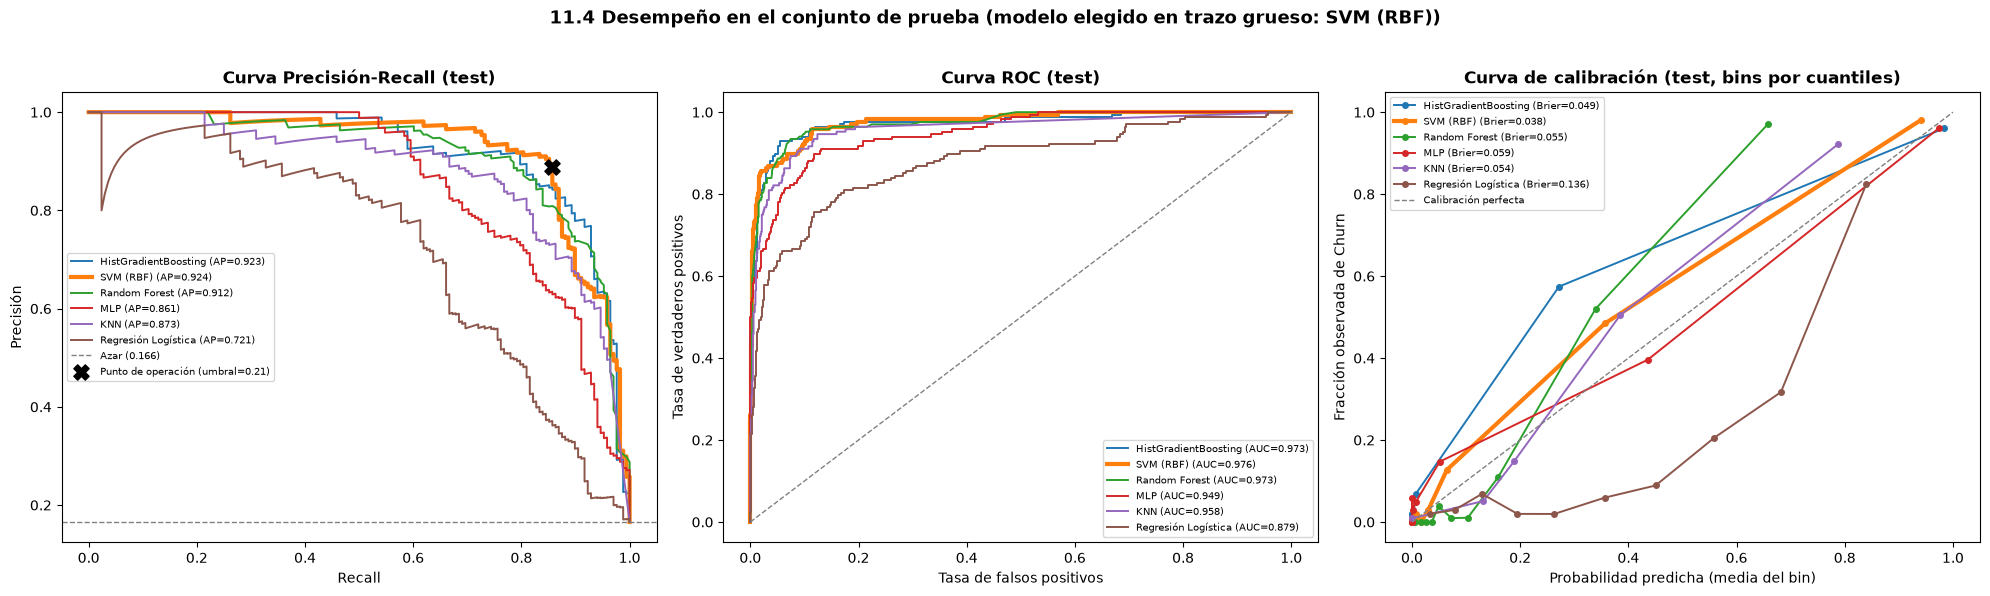

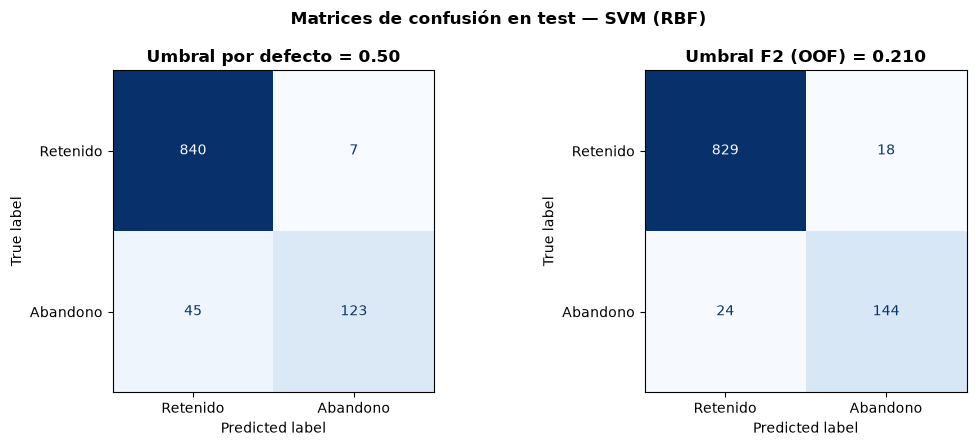

In [9]:
paleta = dict(zip(tabla_cv.index, sns.color_palette("tab10", len(tabla_cv))))
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

for nombre in tabla_cv.index:
    lw = 3 if nombre == MODELO_ELEGIDO else 1.4
    pr_, rc_, _ = precision_recall_curve(y_test, p_test[nombre])
    axes[0].plot(rc_, pr_, lw=lw, color=paleta[nombre],
                 label=f"{nombre} (AP={average_precision_score(y_test, p_test[nombre]):.3f})")
    fpr, tpr, _ = roc_curve(y_test, p_test[nombre])
    axes[1].plot(fpr, tpr, lw=lw, color=paleta[nombre],
                 label=f"{nombre} (AUC={roc_auc_score(y_test, p_test[nombre]):.3f})")
    fp_, mp_ = calibration_curve(y_test, p_test[nombre], n_bins=10, strategy="quantile")
    axes[2].plot(mp_, fp_, marker="o", ms=4, lw=lw, color=paleta[nombre],
                 label=f"{nombre} (Brier={brier_score_loss(y_test, p_test[nombre]):.3f})")

axes[0].axhline(y_test.mean(), color="gray", ls="--", lw=1, label=f"Azar ({y_test.mean():.3f})")
r_sel = recall_score(y_test, yhat_sel); p_sel_pt = precision_score(y_test, yhat_sel)
axes[0].scatter(r_sel, p_sel_pt, s=120, color="black", zorder=5, marker="X", label=f"Punto de operación (umbral={UMBRAL:.2f})")
axes[0].set(xlabel="Recall", ylabel="Precisión", title="Curva Precisión-Recall (test)")
axes[1].plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
axes[1].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="Curva ROC (test)")
axes[2].plot([0, 1], [0, 1], color="gray", ls="--", lw=1, label="Calibración perfecta")
axes[2].set(xlabel="Probabilidad predicha (media del bin)", ylabel="Fracción observada de Churn",
            title="Curva de calibración (test, bins por cuantiles)")
for ax in axes:
    ax.legend(fontsize=7.5, loc="best")
    ax.title.set_fontweight("bold")
fig.suptitle(f"11.4 Desempeño en el conjunto de prueba (modelo elegido en trazo grueso: {MODELO_ELEGIDO})",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
guardar(fig, "11_4_curvas_pr_roc_calibracion_test")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (thr, titulo) in zip(axes, [(0.5, "Umbral por defecto = 0.50"), (UMBRAL, f"Umbral F{BETA_UMBRAL} (OOF) = {UMBRAL:.3f}")]):
    ConfusionMatrixDisplay.from_predictions(y_test, (p_sel_test >= thr).astype(int), display_labels=["Retenido", "Abandono"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(titulo, fontweight="bold")
    ax.grid(False)
fig.suptitle(f"Matrices de confusión en test — {MODELO_ELEGIDO}", fontweight="bold")
plt.tight_layout()
guardar(fig, "11_4_matrices_confusion_test")

plt.show()

En las curvas y la calibración la SVM sale mejor parada: tiene el PR-AUC y el ROC-AUC más altos del test (0,924 y 0,976) y el menor Brier (0,038), seguida por el HGB (0,049). La calibración se ve buena en los intervalos observados y las matrices de confusión respaldan el umbral elegido.

### Lectura de negocio: ganancia y lift

,clientes contactados,abandonos capturados,% de abandonos capturados,precisión en el grupo (%),lift
% de clientes contactados (mayor riesgo),,,,,
5,51,50,29.8,98.0,5.92
10,102,100,59.5,98.0,5.92
15,153,140,83.3,91.5,5.53
20,203,149,88.7,73.4,4.43
30,305,162,96.4,53.1,3.21
40,406,165,98.2,40.6,2.46
50,508,165,98.2,32.5,1.96


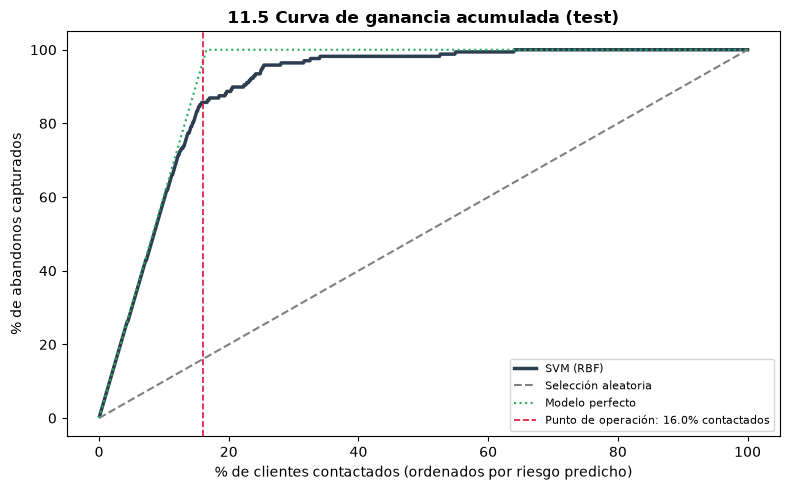

In [10]:
orden_riesgo = np.argsort(-p_sel_test)
y_ord = yv[orden_riesgo]
total_churn = y_ord.sum()
filas_lift = []
for pct in [5, 10, 15, 20, 30, 40, 50]:
    k = int(np.ceil(len(y_ord) * pct / 100))
    capt = y_ord[:k].sum()
    filas_lift.append({
        "% de clientes contactados (mayor riesgo)": pct, "clientes contactados": k,
        "abandonos capturados": int(capt), "% de abandonos capturados": round(100 * capt / total_churn, 1),
        "precisión en el grupo (%)": round(100 * capt / k, 1), "lift": round((capt / k) / yv.mean(), 2),
    })
tabla_lift = pd.DataFrame(filas_lift).set_index("% de clientes contactados (mayor riesgo)")
display(tabla_lift)
exportar(tabla_lift, "11_5_tabla_lift_test")

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(1, len(y_ord) + 1) / len(y_ord)
ax.plot(100 * x, 100 * np.cumsum(y_ord) / total_churn, lw=2.5, color="#2c3e50", label=MODELO_ELEGIDO)
ax.plot([0, 100], [0, 100], ls="--", color="gray", label="Selección aleatoria")
ax.plot([0, 100 * yv.mean(), 100], [0, 100, 100], ls=":", color="#27ae60", label="Modelo perfecto")
ax.axvline(100 * yhat_sel.mean(), color="crimson", ls="--", lw=1.2,
           label=f"Punto de operación: {100 * yhat_sel.mean():.1f}% contactados")
ax.set_xlabel("% de clientes contactados (ordenados por riesgo predicho)")
ax.set_ylabel("% de abandonos capturados")
ax.set_title("11.5 Curva de ganancia acumulada (test)", fontweight="bold")
ax.legend(fontsize=8)
plt.tight_layout()
guardar(fig, "11_5_curva_ganancia_test")

plt.show()

Si contactáramos solo al 20 % de los clientes con mayor riesgo, capturaríamos el 88,7 % de los abandonos, es decir, 4,43 veces más que al elegir al azar (lift). Con el 10 % se captura el 59,5 % (lift de 5,92) y con el 15 %, el 83,3 %. La curva de ganancia se separa con claridad de la selección aleatoria, lo que respalda una campaña de retención dirigida a los clientes de mayor riesgo.

### Interpretabilidad: importancia por permutación


,caída media de PR-AUC,desv.
Tenure,0.3745,0.0253
Complain,0.2208,0.0253
NumberOfAddress,0.1190,0.0151
SatisfactionScore,0.1117,0.0124
WarehouseToHome,0.0991,0.0135
DaySinceLastOrder,0.0950,0.0183
CityTier,0.0918,0.0119
PreferredPaymentMode,0.0863,0.0163
PreferedOrderCat,0.0801,0.0106
OrderAmountHikeFromlastYear,0.0740,0.0092


C:\Users\ASUS\AppData\Local\Temp\ipykernel_16528\3329290997.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(perm.importances[[X_test.columns.get_loc(c) for c in orden_imp]].T, vert=False,


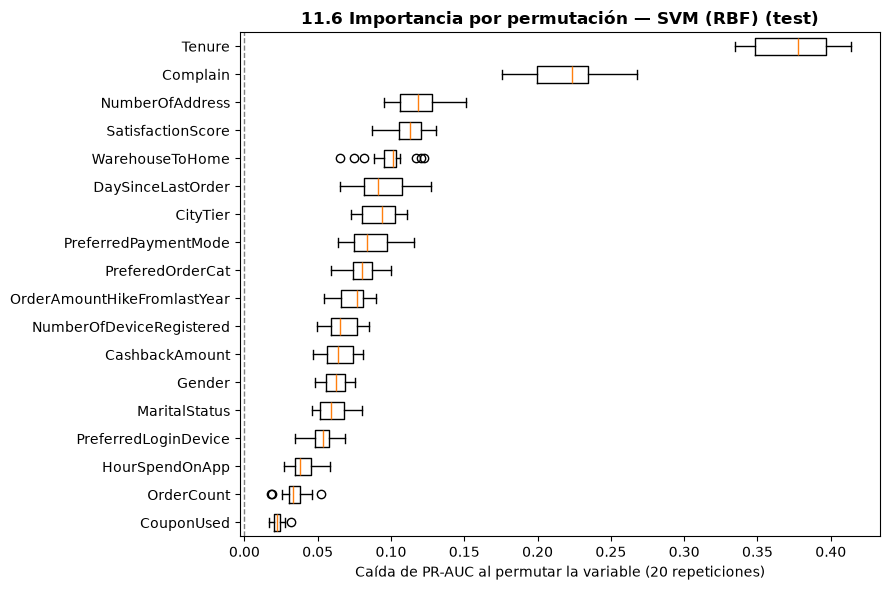

Nota: CashbackAmount y PreferedOrderCat comparten ~84 % de varianza (η² de la sección 5.5); al permutar una, el modelo puede apoyarse en la otra, por lo que su importancia individual tiende a subestimarse.


In [11]:
perm = permutation_importance(modelos_test[MODELO_ELEGIDO], X_test, y_test, scoring="average_precision",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"caída media de PR-AUC": perm.importances_mean, "desv.": perm.importances_std},
                   index=X_test.columns).sort_values("caída media de PR-AUC", ascending=False)
display(imp.round(4))
exportar(imp.round(4), "11_6_importancia_permutacion_test")

fig, ax = plt.subplots(figsize=(9, 6))
orden_imp = imp.index[::-1]
ax.boxplot(perm.importances[[X_test.columns.get_loc(c) for c in orden_imp]].T, vert=False,
           widths=0.6)
ax.set_yticklabels(list(orden_imp))
ax.axvline(0, color="gray", ls="--", lw=1)
ax.set_xlabel("Caída de PR-AUC al permutar la variable (20 repeticiones)")
ax.set_title(f"11.6 Importancia por permutación — {MODELO_ELEGIDO} (test)", fontweight="bold")
plt.tight_layout()
guardar(fig, "11_6_importancia_permutacion")

plt.show()

print("Nota: CashbackAmount y PreferedOrderCat comparten ~84 % de varianza (η² de la sección 5.5); al permutar una,"
      " el modelo puede apoyarse en la otra, por lo que su importancia individual tiende a subestimarse.")

Según la importancia por permutación, las variables que más pesan en el modelo son Tenure (caída de 0,37 en el PR-AUC), Complain (0,22), NumberOfAddress (0,12), SatisfactionScore (0,11) y WarehouseToHome (0,10). Hay que leer con cuidado el caso de CashbackAmount y PreferedOrderCat, que comparten cerca del 84 % de varianza: al permutar una, el modelo se apoya en la otra, así que la importancia individual de ambas queda subestimada y no significa que no tengan efecto.

### Resumen automático

In [12]:
fila = tabla_test.loc[MODELO_ELEGIDO]
top_imp = imp.head(5).index.tolist()
print("=" * 90)
print("RESUMEN DE LA EVALUACIÓN FINAL")
print("=" * 90)
print(f"• Ranking CV repetida ({N_SPLITS}x{N_REPEATS}, PR-AUC): " +
      " > ".join(f"{m} ({v:.3f})" for m, v in tabla_cv['PR-AUC CV (media)'].items()))
print(f"• Modelo final: {MODELO_ELEGIDO} (mínimo costo OOF 5:1). Alternativa: HistGradientBoosting.")
print(f"• Umbral fijado en OOF de train (costo 5:1 para SVM; F2 para el resto): {UMBRAL:.3f} (vs. 0.5 por defecto).")
print(f"• Test ({len(yv)} clientes, prevalencia {yv.mean():.1%}):")
for met in ["PR-AUC", "ROC-AUC", "Recall", "Precisión", f"F{BETA_UMBRAL}", "Brier"]:
    print(f"    - {met:<9}= {ic_test.loc[met, 'Estimación']:.3f}  [IC95 {ic_test.loc[met, 'IC95 inf']:.3f} – {ic_test.loc[met, 'IC95 sup']:.3f}]")
print(f"• Brecha test - CV en PR-AUC: {fila['Δ PR-AUC (test - CV)']:+.3f} "
      f"({'dentro' if abs(fila['Δ PR-AUC (test - CV)']) <= 2 * tabla_cv.loc[MODELO_ELEGIDO, 'PR-AUC CV (desv.)'] else 'fuera'} de ±2 desv. de la CV).")
t20 = tabla_lift.loc[20]
print(f"• Negocio: contactando al 20 % de mayor riesgo se captura el {t20['% de abandonos capturados']}% de los abandonos "
      f"(lift = {t20['lift']}).")
print(f"• Variables más influyentes (permutación en test): {top_imp}.")
print("=" * 90)

RESUMEN DE LA EVALUACIÓN FINAL
• Ranking CV repetida (5x5, PR-AUC): HistGradientBoosting (0.878) > SVM (RBF) (0.858) > Random Forest (0.846) > MLP (0.800) > KNN (0.781) > Regresión Logística (0.698)
• Modelo final: SVM (RBF) (mínimo costo OOF 5:1). Alternativa: HistGradientBoosting.
• Umbral fijado en OOF de train (costo 5:1 para SVM; F2 para el resto): 0.210 (vs. 0.5 por defecto).
• Test (1015 clientes, prevalencia 16.6%):
    - PR-AUC   = 0.924  [IC95 0.881 – 0.960]
    - ROC-AUC  = 0.976  [IC95 0.957 – 0.989]
    - Recall   = 0.857  [IC95 0.781 – 0.920]
    - Precisión= 0.889  [IC95 0.829 – 0.944]
    - F2       = 0.863  [IC95 0.800 – 0.914]
    - Brier    = 0.038  [IC95 0.027 – 0.052]
• Brecha test - CV en PR-AUC: +0.066 (fuera de ±2 desv. de la CV).
• Negocio: contactando al 20 % de mayor riesgo se captura el 88.7% de los abandonos (lift = 4.43).
• Variables más influyentes (permutación en test): ['Tenure', 'Complain', 'NumberOfAddress', 'SatisfactionScore', 'WarehouseToHome'].


In [13]:
guardar_estado("4_evaluation",
    BETA_UMBRAL=BETA_UMBRAL,
    COSTO_FN=COSTO_FN,
    COSTO_FP=COSTO_FP,
    N_REPEATS=N_REPEATS,
    N_SPLITS=N_SPLITS,
    N_BOOT=N_BOOT,
    cv_rep=cv_rep,
    pr=pr,
    X_test=X_test,
    y_test=y_test,
    grid_hgb=grid_hgb,
    modelo_hgb_final=modelo_hgb_final,
    modelos_finales=modelos_finales,
    tabla_cv=tabla_cv,
    oof=oof,
    umbrales=umbrales,
    tabla_oof=tabla_oof,
    MODELO_ELEGIDO=MODELO_ELEGIDO,
    MODELO_FINAL=MODELO_FINAL,
    MODELO_GRUPO=MODELO_GRUPO,
    MODELO_CLIENTE=MODELO_CLIENTE,
    POLITICA_SELECCION=POLITICA_SELECCION,
    CRITERIO_SELECCION=CRITERIO_SELECCION,
    UMBRAL=UMBRAL,
    p_test=p_test,
    modelos_test=modelos_test,
    tabla_test=tabla_test,
    tabla_costo=tabla_costo,
    umbrales_costo=UMBRALES_COSTO,
)


WindowsPath('C:/Users/ASUS/Desktop/V8-final/data/processed/estado_4_evaluation.joblib')

## Cierre de la evaluación

La decisión final es la SVM con kernel RBF y umbral de 0,21, elegida por tener el menor costo OOF; el HGB queda como alternativa por su mayor recall. En el conjunto de prueba la SVM alcanza un PR-AUC de 0,924, un ROC-AUC de 0,976 y un Brier de 0,038, y al contactar al 20 % de los clientes con mayor riesgo captura el 88,7 % de los abandonos. La auditoría por grupos, que desarrollamos en 5_pca_umap, también respalda esta decisión. La evidencia detallada está en las tablas guardadas en reports/.